
Every transformer based model (GPT, LLaMA, BERT, etc) starts the same way: a lookup table. The flow is always: text → tokens (integers) → embeddings (vectors) → transformer layers.

Tokenization splits text into integer IDs, but those IDs carry zero semantic information. For example, token 4821 ("cat") is not mathematically closer to token 2955 ("dog") than to token 9173 ("airplane"). The embedding layer maps each integer to a learned dense vector: 768 dimensions in GPT-2, 4096 in LLaMA 7B, where semantic proximity is real and measurable.

GPT-2 for instance stores two embedding matrices:
- wte (50257 x 768) for token identity
- wpe (1024 x 768) for position

Without position encoding, "the cat sat on the mat" and "mat the on sat cat the" produce identical representations. The input to the first transformer block is simply wte[token_id] + wpe[position]: two table lookups and one addition.

Modern architectures like LLaMA replace the stored wpe with rotary position embeddings (RoPE), computing positions on the fly and removing the hard sequence length ceiling.

In [3]:
import json
import struct
import os
import re
import numpy as np

MODEL_DIR = "gpt2_weights"


# --- Load weights ---
def parse_safetensors(path):
    with open(path, "rb") as f:
        header_len = struct.unpack("<Q", f.read(8))[0]
        header = json.loads(f.read(header_len))
        data_start = 8 + header_len
        tensors = {}
        for name, info in header.items():
            if name == "__metadata__":
                continue
            dtype = {"F32": np.float32, "F16": np.float16}[info["dtype"]]
            start, end = info["data_offsets"]
            f.seek(data_start + start)
            tensors[name] = np.frombuffer(f.read(end - start), dtype=dtype).reshape(info["shape"])
        return tensors

weights = parse_safetensors(os.path.join(MODEL_DIR, "model.safetensors"))


# --- Load tokenizer ---
with open(os.path.join(MODEL_DIR, "vocab.json")) as f:
    vocab = json.load(f)
with open(os.path.join(MODEL_DIR, "merges.txt")) as f:
    merges_raw = f.read().strip().split("\n")[1:]

id_to_token = {v: k for k, v in vocab.items()}
bpe_ranks = {tuple(m.split()): i for i, m in enumerate(merges_raw)}

def bytes_to_unicode():
    bs = list(range(33, 127)) + list(range(161, 173)) + list(range(174, 256))
    cs = bs[:]
    n = 0
    for b in range(256):
        if b not in bs:
            bs.append(b)
            cs.append(256 + n)
            n += 1
    return dict(zip(bs, [chr(c) for c in cs]))

byte_encoder = bytes_to_unicode()
byte_decoder = {v: k for k, v in byte_encoder.items()}
GPT2_PATTERN = re.compile(r"""'s|'t|'re|'ve|'m|'ll|'d| ?\w+| ?[^\s\w]+|\s+(?!\S)|\s+""")

def get_pairs(tokens):
    return set(zip(tokens[:-1], tokens[1:]))

def bpe_merge(tokens):
    while True:
        pairs = get_pairs(tokens)
        if not pairs:
            break
        best = min(pairs, key=lambda p: bpe_ranks.get(p, float("inf")))
        if best not in bpe_ranks:
            break
        first, second = best
        new = []
        i = 0
        while i < len(tokens):
            if i < len(tokens)-1 and tokens[i] == first and tokens[i+1] == second:
                new.append(first + second)
                i += 2
            else:
                new.append(tokens[i])
                i += 1
        tokens = new
    return tokens

def encode(text):
    ids = []
    for chunk in re.findall(GPT2_PATTERN, text):
        uc = [byte_encoder[b] for b in chunk.encode("utf-8")]
        for t in bpe_merge(uc):
            ids.append(vocab[t])
    return ids

def decode(token_ids):
    text = "".join(id_to_token[i] for i in token_ids)
    return bytes([byte_decoder[c] for c in text]).decode("utf-8", errors="replace")

print(f"Weights loaded: {len(weights)} tensors")
print(f"Tokenizer ready: {len(vocab):,} tokens")


Weights loaded: 160 tensors
Tokenizer ready: 50,257 tokens


## 1. Token Embeddings: The lookup table

The token embedding matrix `wte.weight` has shape `[50257, 768]`.

- **50,257 rows** — one for every token in the vocabulary
- **768 columns** — the embedding dimension (d_model)

To embed a token, you just **index into this matrix**. Token ID 9246 → row 9246.  
No multiplication needed — it's a pure table lookup, like indexing into an array.

```
wte.weight:   50257 rows x 768 columns

           col0    col1    col2    ...   col767
row 0    [ 0.012, -0.023,  0.045, ...,  0.008 ]   <- token 0
row 1    [-0.034,  0.011, -0.007, ...,  0.015 ]   <- token 1
...
row 9246 [ 0.041, -0.019,  0.033, ..., -0.028 ]   <- "cat"
...
row 50256[ 0.003,  0.001, -0.002, ...,  0.001 ]   <- <|endoftext|>
```

Think of it like a hash map: `embedding = wte[token_id]`

**What do the 768 numbers in a row mean?**

Nobody hand-designed them — they were learned during training via gradient descent.
Through training, dimensions self-organize into features: some correlate with noun-ness vs verb-ness,
others with sentiment, formality, or topic. Most dimensions encode **mixtures** of features, not clean labels.

In [6]:
wte = weights["wte.weight"]  # Token embedding table

print(f"Token embedding matrix (wte.weight)")
print(f"  Shape: {wte.shape}")
print(f"  Dtype: {wte.dtype}")
print(f"  Size:  {wte.nbytes / (1024*1024):.1f} MB")
print()

# Look up embeddings for a sentence
text = "The cat sat"
token_ids = encode(text)

print(f"Text: '{text}'")
print(f"Token IDs: {token_ids}")
print()

for tid in token_ids:
    embedding = wte[tid]  # Just array indexing!
    token_str = decode([tid])
    print(f"  Token '{token_str}' (ID {tid}):")
    print(f"    Vector: [{embedding[0]:.4f}, {embedding[1]:.4f}, {embedding[2]:.4f}, ..., {embedding[-1]:.4f}]")
    print(f"    Shape:  {embedding.shape}")
    print(f"    Norm:   {np.linalg.norm(embedding):.4f}")

Token embedding matrix (wte.weight)
  Shape: (50257, 768)
  Dtype: float32
  Size:  147.2 MB

Text: 'The cat sat'
Token IDs: [464, 3797, 3332]

  Token 'The' (ID 464):
    Vector: [-0.0686, -0.0203, 0.0645, ..., 0.0031]
    Shape:  (768,)
    Norm:   2.7203
  Token ' cat' (ID 3797):
    Vector: [0.0100, 0.0366, 0.1640, ..., -0.0695]
    Shape:  (768,)
    Norm:   3.2578
  Token ' sat' (ID 3332):
    Vector: [0.0207, -0.1156, 0.0208, ..., -0.0454]
    Shape:  (768,)
    Norm:   3.2772


## 2. Positional Embeddings


Token embeddings tell the model **what** a token is, but not **where** it appears.

**Why this matters:** addition is commutative. If you just add up token embeddings for
"dog bites man" and "man bites dog", you get the same result. The model has no idea which word came first.

Position embeddings fix this. `wpe.weight` has shape `[1024, 768]`:
- **1024 rows** — one for each possible position (GPT-2's max sequence length)
- **768 columns** — same dimension as token embeddings (so they can be added)

**Where does the position come from?** Just the index in the token list. You tokenize the text,
and whatever order the tokens come out in, that's their position. First token → position 0, second → position 1, etc.

```python
token_ids = encode("The cat sat")  # [464, 9246, 3332]
# index 0 → "The" → wpe[0]
# index 1 → "cat" → wpe[1]
# index 2 → "sat" → wpe[2]
```

**Where do the values come from?** Same place as `wte` — `wpe.weight` is a learned weight matrix
stored in the model file. Gradient descent adjusted every value during training. Nobody hand-coded
what each position vector should look like.

1024 rows = GPT-2's max sequence length. It literally can't process more than 1024 tokens
because there's no position embedding for position 1024+.

The final input to the model is: `token_embedding + position_embedding`

```
 Position 0: wte["The"]  + wpe[0]  = input vector for "The" at position 0
 Position 1: wte["cat"]  + wpe[1]  = input vector for "cat" at position 1
 Position 2: wte["sat"]  + wpe[2]  = input vector for "sat" at position 2
```

**Why does addition work?** The token vector says **what** ("cat"). The position vector says **where**
("second slot"). During training, the model learned to encode these two signals in non-overlapping
directions within the 768 dimensions, so they don't interfere with each other.

Analogy: a shipping label. The item description says what's in the box. The tracking number says
where it is in the delivery sequence. Both stamped on the same label — the warehouse reads whichever piece it needs.

In [10]:
wpe = weights["wpe.weight"]  # Position embedding table

print(f"Position embedding matrix (wpe.weight)")
print(f"  Shape: {wpe.shape}")
print(f"  Max sequence length: {wpe.shape[0]}")
print()

# Build the full input embeddings for "The cat sat"
token_ids = encode("The cat sat")
seq_len = len(token_ids)

token_embeddings = wte[token_ids]        # (seq_len, 768) — what each token is
position_embeddings = wpe[:seq_len]       # (seq_len, 768) — where each token is
input_embeddings = token_embeddings + position_embeddings  # element-wise add

print(f"Token embeddings shape:    {token_embeddings.shape}")
print(f"Position embeddings shape: {position_embeddings.shape}")
print(f"Input embeddings shape:    {input_embeddings.shape}")
print()
print("This is the actual input to the first transformer block.")
print("A matrix of shape (seq_len, 768) — one 768-dim vector per token.")

Position embedding matrix (wpe.weight)
  Shape: (1024, 768)
  Max sequence length: 1024

Token embeddings shape:    (3, 768)
Position embeddings shape: (3, 768)
Input embeddings shape:    (3, 768)

This is the actual input to the first transformer block.
A matrix of shape (seq_len, 768) — one 768-dim vector per token.


## Token embeddings : Do Embeddings Capture Meaning?


These 768-dimensional vectors aren't random — they were learned during training.  
Similar words should have similar vectors. Let's check using **cosine similarity**:

$$\text{similarity}(a, b) = \frac{a \cdot b}{\|a\| \cdot \|b\|}$$

Result is between -1 (opposite) and +1 (identical direction).  
Think of it like: two vectors pointing the same direction = similar meaning.

In [11]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def get_embedding(word):
    """Get the token embedding for a single-token word."""
    ids = encode(word)
    if len(ids) == 1:
        return wte[ids[0]]
    # For multi-token words, average the embeddings
    return np.mean(wte[ids], axis=0)

# Compare word pairs
pairs = [
    (" king", " queen"),
    (" king", " throne"),
    (" king", " potato"),
    (" cat", " dog"),
    (" cat", " server"),
    (" fast", " quick"),
    (" fast", " slow"),
    (" GPU", " CPU"),
    (" GPU", " sandwich"),
]

print(f"{'Word A':<12s} {'Word B':<12s} {'Similarity':>10s}  Interpretation")
print("-" * 65)
for a, b in pairs:
    sim = cosine_similarity(get_embedding(a), get_embedding(b))
    bar = "#" * int(max(0, sim) * 30)
    label = "high" if sim > 0.5 else "medium" if sim > 0.2 else "low"
    print(f"{a:<12s} {b:<12s} {sim:>10.4f}  {bar} ({label})")

Word A       Word B       Similarity  Interpretation
-----------------------------------------------------------------
 king         queen           0.6573  ################### (high)
 king         throne          0.5060  ############### (high)
 king         potato          0.3010  ######### (medium)
 cat          dog             0.5498  ################ (high)
 cat          server          0.2269  ###### (medium)
 fast         quick           0.5772  ################# (high)
 fast         slow            0.5100  ############### (high)
 GPU          CPU             0.6756  #################### (high)
 GPU          sandwich        0.2397  ####### (medium)


## Position Embeddings: Do Nearby Positions Look Similar?

Intuition says positions close together should have more similar embeddings than positions far apart.  
Let's verify: how does similarity decay with distance?

In [12]:
# Compare position 0 to positions 1, 10, 100, 500, 1000
pos0 = wpe[0]

print("Position embedding similarity (relative to position 0):")
print(f"{'Position':<12s} {'Distance':>10s} {'Cosine Sim':>12s}")
print("-" * 38)

for pos in [1, 2, 5, 10, 50, 100, 500, 1023]:
    sim = cosine_similarity(pos0, wpe[pos])
    bar = "#" * int(max(0, (sim + 1) / 2) * 20)  # normalize to 0-1 for display
    print(f"  pos {pos:<6d} {pos:>10d} {sim:>12.4f}  {bar}")

print()
print("Nearby positions are more similar — the model can sense distance.")
print("This is how the model knows word order without explicit position markers.")

Position embedding similarity (relative to position 0):
Position       Distance   Cosine Sim
--------------------------------------
  pos 1               1       0.5242  ###############
  pos 2               2       0.5021  ###############
  pos 5               5       0.4890  ##############
  pos 10             10       0.4443  ##############
  pos 50             50       0.3645  #############
  pos 100           100       0.2991  ############
  pos 500           500       0.0612  ##########
  pos 1023         1023      -0.0485  #########

Nearby positions are more similar — the model can sense distance.
This is how the model knows word order without explicit position markers.


In [15]:
# Now compare position 50 to positions 1, 10, 100, 500, 1000
pos50 = wpe[50]

print("Position embedding similarity (relative to position 50):")
print(f"{'Position':<12s} {'Distance':>10s} {'Cosine Sim':>12s}")
print("-" * 38)

for pos in [1, 2, 5, 10, 50, 100, 500, 1023]:
    dist = abs(pos - 50)
    sim = cosine_similarity(pos50, wpe[pos])
    bar = "#" * int(max(0, (sim + 1) / 2) * 20)  # normalize to 0-1 for display
    print(f"  pos {pos:<6d} {dist:>10d} {sim:>12.4f}  {bar}")

print()
print("Nearby positions are more similar — the model can sense distance.")
print("This is how the model knows word order without explicit position markers.")

Position embedding similarity (relative to position 50):
Position       Distance   Cosine Sim
--------------------------------------
  pos 1              49       0.3951  #############
  pos 2              48       0.3984  #############
  pos 5              45       0.4330  ##############
  pos 10             40       0.5244  ###############
  pos 50              0       1.0000  ####################
  pos 100            50       0.6376  ################
  pos 500           450       0.4168  ##############
  pos 1023          973      -0.0150  #########

Nearby positions are more similar — the model can sense distance.
This is how the model knows word order without explicit position markers.


## Putting It Together — The Full Embedding Pipeline

Here's the complete embedding function that will be the first step of our forward pass:

```
"The cat sat on the mat"
         │
   encode()          (tokenizer)
         │
  [464, 9246, 3332, 319, 262, 2603]
         │
   wte[ids]          (token lookup — what each token is)
         │
   + wpe[:seq_len]   (position lookup — where each token is)
         │
   (6, 768) matrix   (ready for transformer blocks)
```

In [16]:
def embed(token_ids, wte, wpe):
    """Convert token IDs to input embeddings.
    
    Like DNS resolution: token ID -> vector the model can route.
    
    token_ids: list of integers
    wte: token embedding matrix [vocab_size, d_model]
    wpe: position embedding matrix [max_seq_len, d_model]
    returns: numpy array of shape (seq_len, d_model)
    """
    seq_len = len(token_ids)
    token_emb = wte[token_ids]      # (seq_len, 768)
    pos_emb = wpe[:seq_len]         # (seq_len, 768)
    return token_emb + pos_emb      # (seq_len, 768)

# Test it end-to-end
text = "The cat sat on the mat"
token_ids = encode(text)
embeddings = embed(token_ids, wte, wpe)

print(f"Input text:     '{text}'")
print(f"Token IDs:      {token_ids}")
print(f"Embedding shape: {embeddings.shape}")
print()
print(f"Each row is a 768-dimensional vector.")
print(f"This {embeddings.shape[0]}x{embeddings.shape[1]} matrix is the input to transformer block h.0.")
print()
print(f"Memory for this input: {embeddings.nbytes} bytes ({embeddings.nbytes/1024:.1f} KB)")
print(f"Memory for the embedding tables: {(wte.nbytes + wpe.nbytes) / (1024*1024):.1f} MB")

Input text:     'The cat sat on the mat'
Token IDs:      [464, 3797, 3332, 319, 262, 2603]
Embedding shape: (6, 768)

Each row is a 768-dimensional vector.
This 6x768 matrix is the input to transformer block h.0.

Memory for this input: 18432 bytes (18.0 KB)
Memory for the embedding tables: 150.2 MB


## Key takeaways:

- `wte[token_id]` gives you token embeddings and is a vector of [vocab size * d_model] and in this case [50257 * 768]
- `wpe[position]` gives you the positional embeddings and is a vector of [max sequence lenght * d_model] and in this case [1024 * 768]
- Both are learned vectors using gradient decent during training - similar words are closer to each other in wte , and closer words in the token seq are closer to each other in wpe
- Final output/ input to the transformer = `wte[token_ids] + wpe[:seq_len]`  =  `(seq_len, 768)`matrix
  example: 
    
    emb["the"] = wte["the"] + wpe[0]

    emb["cat"] = wte["cat"] + wpe[1]
    
    emb["sat"] = wte["sat"] + wpe[2]

    therefore final matrix: [seq_length * d_model]
- these embedding tables take up memory
  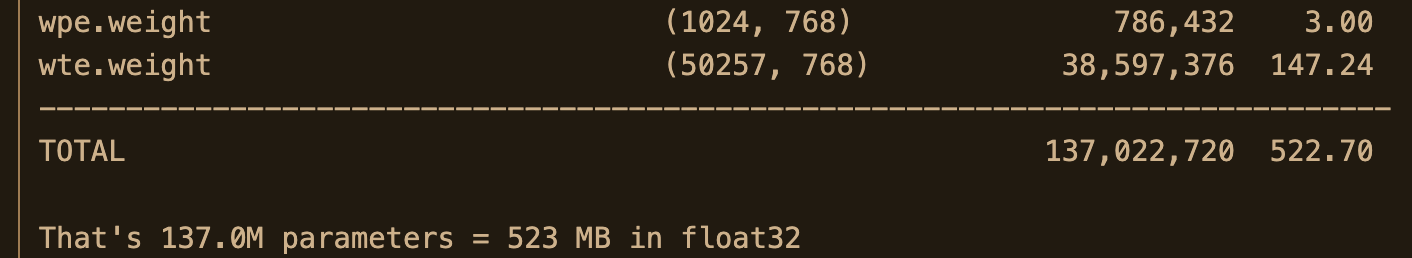

  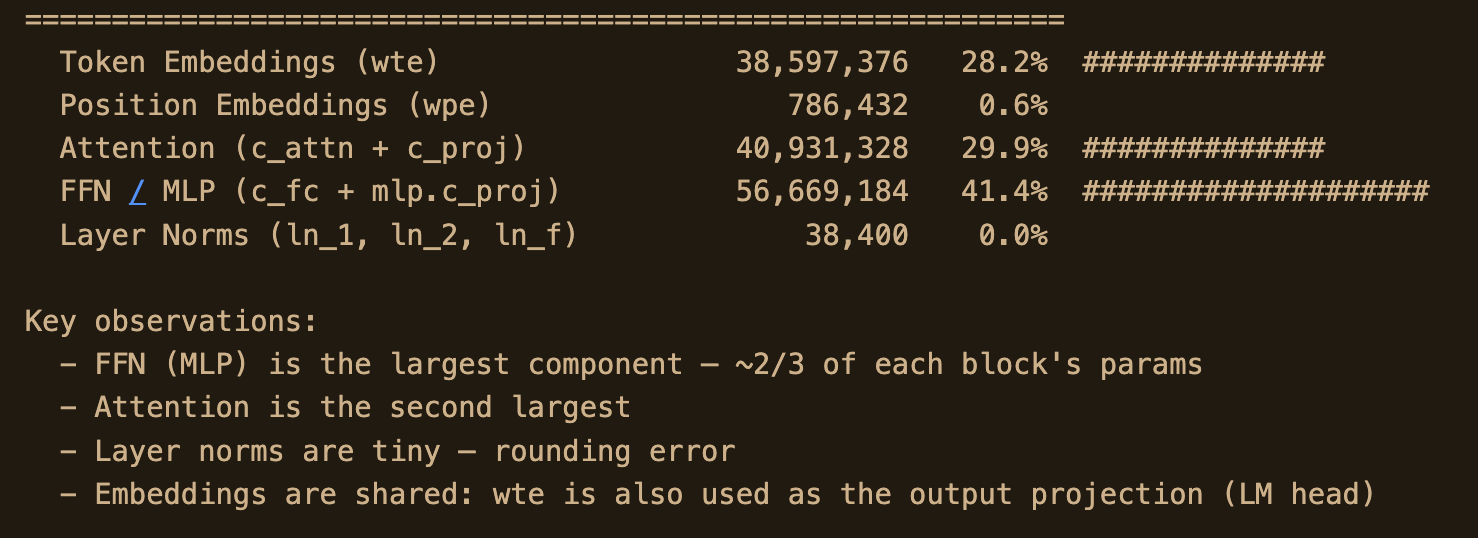
     